In [8]:
#Q1
import re
import nltk
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords
from nltk.probability import FreqDist

nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')

text = """Artificial intelligence is transforming the world.
It helps people solve complex problems and automate tasks.
Machine learning allows computers to learn from data.
AI is used in healthcare, education, and transportation.
I enjoy learning about AI because it makes technology smarter."""

text = text.lower()
text = re.sub(r'[^\w\s]', '', text)

words = word_tokenize(text)
sentences = sent_tokenize(text)

print("Processed Text:", text)
print("Words:", words)
print("Sentences:", sentences)
print("Split:", text.split())
print("Word Tokenize:", word_tokenize(text))

stop = set(stopwords.words('english'))
newwords = [word for word in words if word not in stop]

print("Words after Stopword Removal:", newwords)

freq = FreqDist(newwords)
print("Word Frequency:", freq.most_common())

Processed Text: artificial intelligence is transforming the world
it helps people solve complex problems and automate tasks
machine learning allows computers to learn from data
ai is used in healthcare education and transportation
i enjoy learning about ai because it makes technology smarter
Words: ['artificial', 'intelligence', 'is', 'transforming', 'the', 'world', 'it', 'helps', 'people', 'solve', 'complex', 'problems', 'and', 'automate', 'tasks', 'machine', 'learning', 'allows', 'computers', 'to', 'learn', 'from', 'data', 'ai', 'is', 'used', 'in', 'healthcare', 'education', 'and', 'transportation', 'i', 'enjoy', 'learning', 'about', 'ai', 'because', 'it', 'makes', 'technology', 'smarter']
Sentences: ['artificial intelligence is transforming the world\nit helps people solve complex problems and automate tasks\nmachine learning allows computers to learn from data\nai is used in healthcare education and transportation\ni enjoy learning about ai because it makes technology smarter']
Spl

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [9]:
#Q2
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer

nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

text = """Artificial intelligence is transforming the world.
It helps people solve complex problems and automate tasks.
Machine learning allows computers to learn from data.
AI is used in healthcare, education, and transportation.
I enjoy learning about AI because it makes technology smarter."""

words = re.findall(r'\b[a-zA-Z]+\b', text.lower())
stop = set(stopwords.words('english'))
newwords = [word for word in words if word not in stop]

stemmer = PorterStemmer()
lemma = WordNetLemmatizer()

stem = [stemmer.stem(word) for word in newwords]
lem = [lemma.lemmatize(word) for word in newwords]

print("Original Words:", newwords)
print("Stemmed Words:", stem)
print("Lemmatized Words:", lem)

print("Stemming gives root-like forms.")
print("Lemmatization gives meaningful dictionary words.")
print("Stemming is faster, while lemmatization gives more meaningful results.")

Original Words: ['artificial', 'intelligence', 'transforming', 'world', 'helps', 'people', 'solve', 'complex', 'problems', 'automate', 'tasks', 'machine', 'learning', 'allows', 'computers', 'learn', 'data', 'ai', 'used', 'healthcare', 'education', 'transportation', 'enjoy', 'learning', 'ai', 'makes', 'technology', 'smarter']
Stemmed Words: ['artifici', 'intellig', 'transform', 'world', 'help', 'peopl', 'solv', 'complex', 'problem', 'autom', 'task', 'machin', 'learn', 'allow', 'comput', 'learn', 'data', 'ai', 'use', 'healthcar', 'educ', 'transport', 'enjoy', 'learn', 'ai', 'make', 'technolog', 'smarter']
Lemmatized Words: ['artificial', 'intelligence', 'transforming', 'world', 'help', 'people', 'solve', 'complex', 'problem', 'automate', 'task', 'machine', 'learning', 'allows', 'computer', 'learn', 'data', 'ai', 'used', 'healthcare', 'education', 'transportation', 'enjoy', 'learning', 'ai', 'make', 'technology', 'smarter']
Stemming gives root-like forms.
Lemmatization gives meaningful di

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


In [10]:
#Q3
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

texts = [
    "Artificial intelligence makes computers intelligent and useful.",
    "Machine learning helps computers learn from data.",
    "Artificial intelligence and machine learning improve technology."
]

count = CountVectorizer()
bow = count.fit_transform(texts)

print("Vocabulary:", count.get_feature_names_out())
print("Bag of Words:\n", bow.toarray())

tfidf = TfidfVectorizer()
matrix = tfidf.fit_transform(texts)
words = tfidf.get_feature_names_out()

print("TF-IDF Matrix:\n", matrix.toarray())

for i in range(len(texts)):
    scores = matrix[i].toarray().flatten()
    top = scores.argsort()[::-1][:3]
    print("Text:", texts[i])
    print("Top Keywords:", [(words[j], round(scores[j], 3)) for j in top])

Vocabulary: ['and' 'artificial' 'computers' 'data' 'from' 'helps' 'improve'
 'intelligence' 'intelligent' 'learn' 'learning' 'machine' 'makes'
 'technology' 'useful']
Bag of Words:
 [[1 1 1 0 0 0 0 1 1 0 0 0 1 0 1]
 [0 0 1 1 1 1 0 0 0 1 1 1 0 0 0]
 [1 1 0 0 0 0 1 1 0 0 1 1 0 1 0]]
TF-IDF Matrix:
 [[0.32992832 0.32992832 0.32992832 0.         0.         0.
  0.         0.32992832 0.43381609 0.         0.         0.
  0.43381609 0.         0.43381609]
 [0.         0.         0.31757018 0.41756662 0.41756662 0.41756662
  0.         0.         0.         0.41756662 0.31757018 0.31757018
  0.         0.         0.        ]
 [0.34385143 0.34385143 0.         0.         0.         0.
  0.45212331 0.34385143 0.         0.         0.34385143 0.34385143
  0.         0.45212331 0.        ]]
Text: Artificial intelligence makes computers intelligent and useful.
Top Keywords: [('useful', np.float64(0.434)), ('makes', np.float64(0.434)), ('intelligent', np.float64(0.434))]
Text: Machine learning help

In [11]:
#Q4
import re
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

nltk.download('stopwords')
nltk.download('punkt')
nltk.download('punkt_tab')

text1 = """Artificial intelligence enables machines to learn from data.
It helps automate tasks and solve complex problems.
AI is widely used in healthcare and education.
It improves efficiency and decision making."""

text2 = """Blockchain is a distributed digital ledger.
It stores transactions securely across multiple computers.
Blockchain provides transparency and data integrity.
It is widely used in cryptocurrency and finance."""

stop = set(stopwords.words('english'))

def clean(text):
    text = re.sub(r'[^a-zA-Z\s]', '', text.lower())
    words = word_tokenize(text)
    return [word for word in words if word not in stop]

words1 = clean(text1)
words2 = clean(text2)

print("Technology 1:", words1)
print("Technology 2:", words2)

set1 = set(words1)
set2 = set(words2)

jaccard = len(set1 & set2) / len(set1 | set2)

tfidf = TfidfVectorizer()
matrix = tfidf.fit_transform([text1, text2])
cosine = cosine_similarity(matrix[0:1], matrix[1:2])[0][0]

print("Jaccard Similarity:", round(jaccard, 4))
print("Cosine Similarity:", round(cosine, 4))

print("Jaccard measures common unique words.")
print("Cosine compares TF-IDF weighted text.")
print("Cosine can provide better insights when word importance matters.")

Technology 1: ['artificial', 'intelligence', 'enables', 'machines', 'learn', 'data', 'helps', 'automate', 'tasks', 'solve', 'complex', 'problems', 'ai', 'widely', 'used', 'healthcare', 'education', 'improves', 'efficiency', 'decision', 'making']
Technology 2: ['blockchain', 'distributed', 'digital', 'ledger', 'stores', 'transactions', 'securely', 'across', 'multiple', 'computers', 'blockchain', 'provides', 'transparency', 'data', 'integrity', 'widely', 'used', 'cryptocurrency', 'finance']
Jaccard Similarity: 0.0833
Cosine Similarity: 0.2938
Jaccard measures common unique words.
Cosine compares TF-IDF weighted text.
Cosine can provide better insights when word importance matters.


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


Review: This product is excellent and works perfectly.
Polarity: 1.0
Subjectivity: 1.0
Sentiment: Positive

Review: I love the quality and the amazing design.
Polarity: 0.55
Subjectivity: 0.75
Sentiment: Positive

Review: The product is terrible and completely disappointing.
Polarity: -0.8
Subjectivity: 0.85
Sentiment: Negative

Review: The service was slow and the experience was bad.
Polarity: -0.5
Subjectivity: 0.533
Sentiment: Negative

Review: The product is okay and works as expected.
Polarity: 0.2
Subjectivity: 0.45
Sentiment: Positive



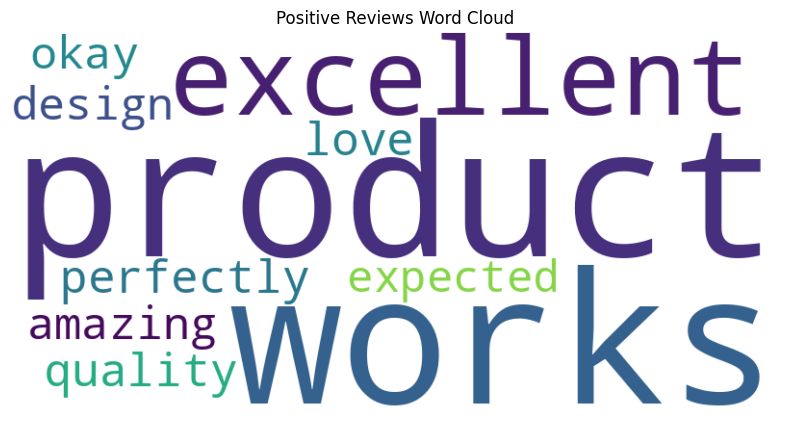

In [12]:
#Q5
import nltk
import matplotlib.pyplot as plt
from textblob import TextBlob
from wordcloud import WordCloud

reviews = [
    "This product is excellent and works perfectly.",
    "I love the quality and the amazing design.",
    "The product is terrible and completely disappointing.",
    "The service was slow and the experience was bad.",
    "The product is okay and works as expected."
]

positive = []

for review in reviews:
    result = TextBlob(review)
    polarity = result.sentiment.polarity
    subjectivity = result.sentiment.subjectivity

    if polarity > 0:
        sentiment = "Positive"
        positive.append(review)
    elif polarity < 0:
        sentiment = "Negative"
    else:
        sentiment = "Neutral"

    print("Review:", review)
    print("Polarity:", round(polarity, 3))
    print("Subjectivity:", round(subjectivity, 3))
    print("Sentiment:", sentiment)
    print()

if positive:
    text = " ".join(positive)
    cloud = WordCloud(width=800, height=400, background_color="white").generate(text)

    plt.figure(figsize=(10, 5))
    plt.imshow(cloud, interpolation="bilinear")
    plt.axis("off")
    plt.title("Positive Reviews Word Cloud")
    plt.show()

In [13]:
#q6
!pip install nltk scikit-learn textblob wordcloud matplotlib tensorflow

import numpy as np
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense

text = """Artificial intelligence is changing the modern world.
Machine learning helps computers learn from examples.
Deep learning uses neural networks to understand complex data.
Technology helps people solve problems and improve their lives.
Computers process information and recognize useful patterns.
Artificial intelligence supports healthcare education and research.
Machine learning models improve when trained with more data.
Technology continues to develop and create new opportunities.
Learning artificial intelligence requires practice and patience.
Neural networks can recognize images text and speech."""

token = Tokenizer()
token.fit_on_texts([text])

total = len(token.word_index) + 1
seq = []

for line in text.split('\n'):
    nums = token.texts_to_sequences([line])[0]
    for i in range(1, len(nums)):
        seq.append(nums[:i + 1])

size = max(len(s) for s in seq)
seq = pad_sequences(seq, maxlen=size, padding='pre')

x = seq[:, :-1]
y = seq[:, -1]

model = Sequential([
    Embedding(total, 32, input_length=size - 1),
    LSTM(64),
    Dense(total, activation='softmax')
])

model.compile(loss='sparse_categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
model.fit(x, y, epochs=300, verbose=0)

def generate(seed, count=15):
    for i in range(count):
        nums = token.texts_to_sequences([seed])[0]
        nums = pad_sequences([nums], maxlen=size - 1, padding='pre')
        pred = np.argmax(model.predict(nums, verbose=0), axis=-1)[0]

        word = ""
        for key, value in token.word_index.items():
            if value == pred:
                word = key
                break

        if not word:
            break

        seed += " " + word

    return seed

print(generate("artificial intelligence"))
print(generate("machine learning"))
print(generate("technology"))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


artificial intelligence supports healthcare education and research research lives data their lives data data data data data
machine learning models improve when trained with more data data data data data data data data lives
technology continues to develop and create new opportunities lives data data data data data data lives
